In [105]:
# For the next 3 exercises, consider the hedge fund index data provided and evaluate the
# performance.
# 1. Performance measures:
# For each hedge fund style, calculate and interpret the following performance measures:
# a. Annualized arithmetic average return
# b. Annualized geometric average return
# c. Annualized volatility of excess returns
# d. Annualized Sharpe ratio
# e. Market beta
# f. Annualized alpha to the market
# g. Annualized Information ratio
# h. Maximum drawdown
# i. Skewness of monthly excess returns
# j. Excess kurtosis of monthly excess returns

# 2. Cumulative return and drawdown:
# Make the following plots for Global Macro Hedge Fund index:
# a. The cumulative return
# b. The drawdown


# 3. Factor models:
# For Equity Long/Short, run two regressions:
# • A univariate regression of the hedge fund index’s excess return on market excess return and
# • A multivariate regression on the market, size, value, and momentum factors
# Afterwards:
# a. Interpret the loadings on the different factors. What do we learn of the investment style?
# b. Compare the multivariate alpha with the alpha from the univariate market regression. Discuss
# the difference in interpretation between the univariate vs. multivariate alphas.


In [177]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [259]:
file_path = "/Users/hapham/Downloads/HW 2 Data CSV.csv"
df = pd.read_csv(file_path, header=2)
df

,Unnamed: 0,Unnamed: 1,RF,Unnamed: 3,Mkt-RF,SMB,HML,UMD,Unnamed: 8,Ln/Sh Eq Hedge Fund USD,Eq Mkt Ntr Hedge Fund USD,Ded Sh Bs Hedge Fund USD,Global Mac Hedge Fund USD,Mngd Fut Hedge Fund USD,Emg Mkts Hedge Fund USD,Evnt Drvn Hedge Fund USD,Cnvrt Arb Hedge Fund USD,Fx Inc Arb Hedge Fund USD,DJCS Hedge Fund USD
0,01/31/1994,NaN,0.25%,NaN,2.90%,0.11%,2.15%,0.09%,NaN,1.17%,-0.55%,-1.63%,0.14%,0.19%,10.51%,3.65%,0.33%,1.27%,1.11%
1,02/28/1994,NaN,0.21%,NaN,-2.63%,2.72%,-1.37%,-0.27%,NaN,-2.50%,0.21%,1.97%,-5.68%,1.17%,-1.17%,-0.18%,0.12%,-2.03%,-4.12%
2,03/31/1994,NaN,0.27%,NaN,-4.85%,-0.90%,1.29%,-1.31%,NaN,-3.91%,-0.25%,7.18%,-4.29%,2.59%,-4.62%,-1.31%,-0.98%,-1.69%,-3.58%
3,04/29/1994,NaN,0.27%,NaN,0.68%,-0.88%,1.66%,0.39%,NaN,-1.57%,0.24%,1.27%,-1.60%,0.84%,-8.37%,-0.67%,-2.53%,-0.22%,-1.75%
4,05/31/1994,NaN,0.32%,NaN,0.62%,-2.05%,0.12%,-2.22%,NaN,0.56%,-0.12%,2.24%,3.78%,0.75%,-0.75%,-0.16%,-1.03%,0.78%,2.22%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218,03/30/2012,NaN,0.00%,NaN,2.52%,-0.19%,0.02%,1.49%,NaN,0.50%,-0.16%,-1.35%,-0.43%,-2.96%,-0.70%,0.79%,0.55%,0.74%,0.05%
219,04/30/2012,NaN,0.00%,NaN,-0.69%,-0.58%,-0.19%,3.94%,NaN,-0.47%,-0.41%,-2.53%,-0.25%,0.43%,0.15%,-0.23%,-0.24%,0.69%,-0.04%
220,05/31/2012,NaN,0.01%,NaN,-6.59%,-0.02%,0.19%,6.65%,NaN,-4.53%,-3.18%,9.03%,0.19%,2.38%,-3.79%,-1.33%,-0.84%,0.24%,-1.33%
221,06/29/2012,NaN,0.00%,NaN,3.85%,0.85%,0.37%,-0.96%,NaN,0.34%,0.92%,-2.72%,-1.37%,-3.56%,-0.14%,-0.18%,0.33%,0.76%,-0.40%


In [260]:
data = df.drop(columns=["Unnamed: 1", "Unnamed: 3","Unnamed: 8" ])
data = data.rename(columns={"Unnamed: 0": "Date"})
data = data.drop(index=222)

def treat(x):
    if '%' in x: return float(x[:-1]) / 100
    else: return x

data = data.map(treat)
data

,Date,RF,Mkt-RF,SMB,HML,UMD,Ln/Sh Eq Hedge Fund USD,Eq Mkt Ntr Hedge Fund USD,Ded Sh Bs Hedge Fund USD,Global Mac Hedge Fund USD,Mngd Fut Hedge Fund USD,Emg Mkts Hedge Fund USD,Evnt Drvn Hedge Fund USD,Cnvrt Arb Hedge Fund USD,Fx Inc Arb Hedge Fund USD,DJCS Hedge Fund USD
0,01/31/1994,0.0025,0.0290,0.0011,0.0215,0.0009,0.0117,-0.0055,-0.0163,0.0014,0.0019,0.1051,0.0365,0.0033,0.0127,0.0111
1,02/28/1994,0.0021,-0.0263,0.0272,-0.0137,-0.0027,-0.0250,0.0021,0.0197,-0.0568,0.0117,-0.0117,-0.0018,0.0012,-0.0203,-0.0412
2,03/31/1994,0.0027,-0.0485,-0.0090,0.0129,-0.0131,-0.0391,-0.0025,0.0718,-0.0429,0.0259,-0.0462,-0.0131,-0.0098,-0.0169,-0.0358
3,04/29/1994,0.0027,0.0068,-0.0088,0.0166,0.0039,-0.0157,0.0024,0.0127,-0.0160,0.0084,-0.0837,-0.0067,-0.0253,-0.0022,-0.0175
4,05/31/1994,0.0032,0.0062,-0.0205,0.0012,-0.0222,0.0056,-0.0012,0.0224,0.0378,0.0075,-0.0075,-0.0016,-0.0103,0.0078,0.0222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,02/29/2012,0.0000,0.0420,-0.0160,-0.0003,-0.0027,0.0264,0.0133,-0.0466,0.0079,0.0120,0.0292,0.0158,0.0188,0.0100,0.0161
218,03/30/2012,0.0000,0.0252,-0.0019,0.0002,0.0149,0.0050,-0.0016,-0.0135,-0.0043,-0.0296,-0.0070,0.0079,0.0055,0.0074,0.0005
219,04/30/2012,0.0000,-0.0069,-0.0058,-0.0019,0.0394,-0.0047,-0.0041,-0.0253,-0.0025,0.0043,0.0015,-0.0023,-0.0024,0.0069,-0.0004
220,05/31/2012,0.0001,-0.0659,-0.0002,0.0019,0.0665,-0.0453,-0.0318,0.0903,0.0019,0.0238,-0.0379,-0.0133,-0.0084,0.0024,-0.0133


In [261]:
# 1. Performance measures:
# For each hedge fund style, calculate and interpret the following performance measures:
# a. Annualized arithmetic average return
# b. Annualized geometric average return
# c. Annualized volatility of excess returns
# d. Annualized Sharpe ratio
# e. Market beta
# f. Annualized alpha to the market
# g. Annualized Information ratio
# h. Maximum drawdown
# i. Skewness of monthly excess returns
# j. Excess kurtosis of monthly excess returns

In [262]:
# 1. Performance measures:
# For each hedge fund style, calculate and interpret the following performance measures:
# a. Annualized arithmetic average return
def ann_arithmetic_return(r):
    r = 12 * r.mean()
    return r
    
# b. Annualized geometric average return
def ann_geometric_return(r):
    r = (np.prod(1+r))**(12/len(r)) - 1
    return r
    
# c. Annualized volatility of excess returns
def ann_volatility(r_excess):
    return np.std(r_excess)* np.sqrt(12)

# d. Annualized Sharpe ratio
def ann_sharpe_ratio(r_excess):
    return (np.mean(r_excess) / np.std(r_excess, ddof=1)) * np.sqrt(12)
    
# e + f. Market beta and annualized alpha

def market_beta_alpha(r_excess, mkt):
    X = sm.add_constant(mkt)
    model = sm.OLS(r_excess, X).fit()
    alpha_monthly = model.params["const"]
    beta = model.params[mkt.name]
    ann_alpha = alpha_monthly*12
    return beta, ann_alpha

# g. Annualized Information ratio
def ann_information_ratio(r_excess, mkt):
    active = r_excess - mkt
    return np.mean(active)/np.std(active, ddof=1) * np.sqrt(12)

# h. Maximum drawdown
def max_drawdown(r):
    cumulative_return = (1+r).cumprod()
    high_water_mark = cumulative_return.cummax()
    dd = (high_water_mark - cumulative_return)/high_water_mark
    return dd.max()

# i. Skewness of monthly excess returns
def recess_skew(r_excess):
    return skew(r_excess)

# j. Excess kurtosis of monthly excess returns
def recess_kurtosis(r_excess):
    return kurtosis(r_excess)

In [263]:
rf = data["RF"]          
mkt = data["Mkt-RF"]     
funds = data.iloc[:, 6:] 

results = {}

for col in funds.columns:
    r = funds[col]       
    r_excess = r - rf    

    results[col] = {
        "Ann. Arithmetic Return": ann_arithmetic_return(r),
        "Ann. Geometric Return": ann_geometric_return(r),
        "Ann. Volatility": ann_volatility(r_excess),
        "Sharpe Ratio": ann_sharpe_ratio(r_excess),
        "Market Beta": market_beta_alpha(r_excess, mkt)[0],
        "Annual Market Alpha": market_beta_alpha(r_excess, mkt)[1],
        "Information Ratio": ann_information_ratio(r_excess, mkt),
        "Max Drawdown": max_drawdown(r),
        "Skewness of Excess Return": recess_skew(r_excess),
        "Kurtosis of Excess Return": recess_kurtosis(r_excess)
    }

performance = pd.DataFrame(results).T
performance

,Ann. Arithmetic Return,Ann. Geometric Return,Ann. Volatility,Sharpe Ratio,Market Beta,Annual Market Alpha,Information Ratio,Max Drawdown,Skewness of Excess Return,Kurtosis of Excess Return
Ln/Sh Eq Hedge Fund USD,0.090416,0.088938,0.098791,0.605755,0.459629,0.031911,-0.009941,0.221490,-0.072117,3.105211
Eq Mkt Ntr Hedge Fund USD,0.052897,0.046821,0.101937,0.219829,0.191397,0.010772,-0.235801,0.451367,-11.913140,161.605800
Ded Sh Bs Hedge Fund USD,-0.026589,-0.040043,0.169313,-0.336056,-0.856559,-0.004721,-0.372068,0.642378,0.648403,1.256933
Global Mac Hedge Fund USD,0.115097,0.116216,0.096202,0.878032,0.151316,0.075419,0.141540,0.270119,-0.098802,3.789744
Mngd Fut Hedge Fund USD,0.061238,0.055848,0.116676,0.263383,-0.071178,0.035146,-0.144338,0.178868,0.024984,-0.051847
Emg Mkts Hedge Fund USD,0.079897,0.070848,0.148589,0.332111,0.544149,0.016231,-0.082399,0.453196,-0.803423,5.000241
Evnt Drvn Hedge Fund USD,0.088308,0.089761,0.062780,0.919710,0.263771,0.041763,-0.024880,0.192924,-2.228765,11.100443
Cnvrt Arb Hedge Fund USD,0.073541,0.073439,0.068858,0.624552,0.173781,0.032491,-0.120927,0.329888,-2.550156,15.439756
Fx Inc Arb Hedge Fund USD,0.052405,0.051899,0.057149,0.383524,0.128111,0.014144,-0.257783,0.290938,-4.202349,28.694674
DJCS Hedge Fund USD,0.084119,0.084382,0.074829,0.715763,0.291372,0.035889,-0.057156,0.198235,-0.267898,2.356625


In [264]:
# //Intepretation:    
# "Ann. Arithmetic Return": annualized returns calculated from the monthly returns, show how much the fund earn per year
# "Ann. Geometric Return": compounded annual annualized return of what we invested
# "Ann. Volatility": annualized of standard deviation of monthly returns
# "Sharpe Ratio": reward per unit of risk
# "Market Beta": Sensitivity of the fund’s excess return to the market excess return
# "Annual Market Alpha": yearly return that above expectation
# "Information Ratio": Measure consistency of outperformance relative to the market
# "Max Drawdown": How much is lost at the worst
# "Skewness of Excess Return": Measures asymmetry in the return distribution
# "Kurtosis of Excess Return": Measures “fat tails” in the return distribution.

In [265]:
# 2. Cumulative return and drawdown:
# Make the following plots for Global Macro Hedge Fund index:
# a. The cumulative return
# b. The drawdown

In [266]:
global_mac_returns = data["Global Mac Hedge Fund USD"].dropna() 

In [267]:
cumulative_return = (1 + global_mac_returns).cumprod()
high_water_mark = cumulative_return.cummax()
dd = (high_water_mark - cumulative_return)/high_water_mark

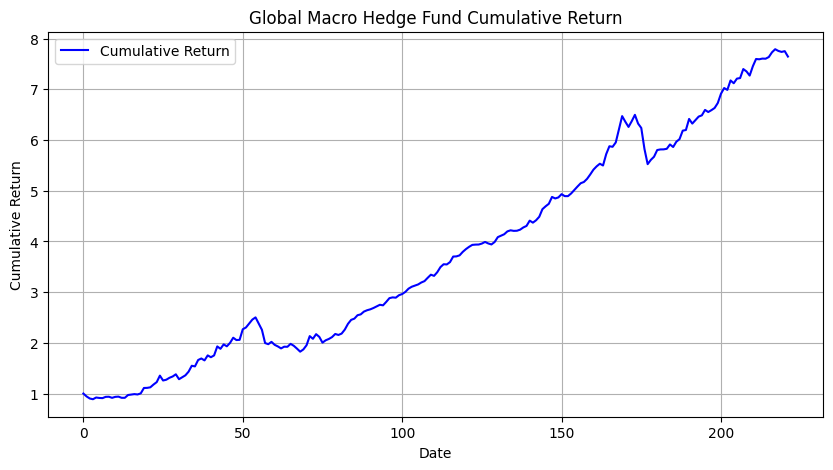

In [268]:
plt.figure(figsize=(10,5))
plt.plot(cumulative_return.index, cumulative_return, label="Cumulative Return", color="blue")
plt.title("Global Macro Hedge Fund Cumulative Return")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(True)
plt.show()

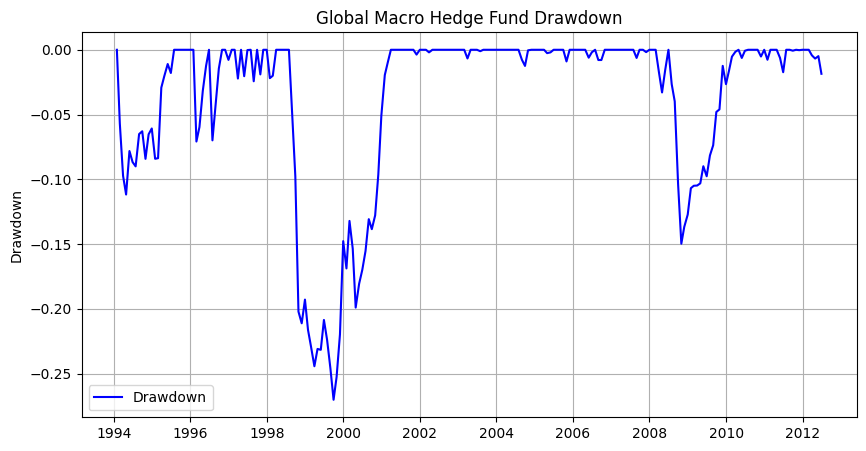

In [269]:
plt.figure(figsize=(10,5))
plt.plot(drawdown, label="Drawdown", color="blue")
plt.title("Global Macro Hedge Fund Drawdown")
plt.ylabel("Drawdown")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 3. Factor models:
# For Equity Long/Short, run two regressions:
# • A univariate regression of the hedge fund index’s excess return on market excess return and
# • A multivariate regression on the market, size, value, and momentum factors
# Afterwards:
# a. Interpret the loadings on the different factors. What do we learn of the investment style?
# b. Compare the multivariate alpha with the alpha from the univariate market regression. Discuss
# the difference in interpretation between the univariate vs. multivariate alphas.

In [270]:
import statsmodels.api as sm
equity_long_short = funds["Ln/Sh Eq Hedge Fund USD"].dropna()

In [271]:
excess = (equity_long_short - rf).dropna()
X_uni = mkt.loc[excess.index]
X_uni = sm.add_constant(X_uni)   
model_uni = sm.OLS(excess, X_uni).fit()
model_uni.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.569
Method:                 Least Squares   F-statistic:                     293.3
Date:                Thu, 25 Sep 2025   Prob (F-statistic):           2.38e-42
Time:                        12:28:36   Log-Likelihood:                 568.74
No. Observations:                 222   AIC:                            -1133.
Df Residuals:                     220   BIC:                            -1127.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0027      0.001      2.100      0.037       0.000       0.005
Mkt-RF         0.4596      0.027     17.126      0.000       0.407       0.513
==============================================================================
Omnibus:                       46.293   Durbin-Watson:                   1.689
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              219.141
Skew:                           0.692   Prob(JB):                     2.59e-48
Kurtosis:                       7.666   Cond. No.                         21.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [316]:
market = data["Mkt-RF"].dropna()
smb = data["SMB"].dropna()
hml = data["HML"].dropna()
umd = data["UMD"].dropna()

In [317]:
excess = data['Ln/Sh Eq Hedge Fund USD'] - data['RF']
factors = pd.concat([market, smb, hml, umd], axis=1)

In [318]:
factors.columns = ["MKT", "SMB", "HML", "UMD"]

In [319]:
data_multi = pd.concat([excess, factors], axis=1).dropna()
data_multi

,0,MKT,SMB,HML,UMD
0,0.0092,0.0290,0.0011,0.0215,0.0009
1,-0.0271,-0.0263,0.0272,-0.0137,-0.0027
2,-0.0418,-0.0485,-0.0090,0.0129,-0.0131
3,-0.0184,0.0068,-0.0088,0.0166,0.0039
4,0.0024,0.0062,-0.0205,0.0012,-0.0222
...,...,...,...,...,...
217,0.0264,0.0420,-0.0160,-0.0003,-0.0027
218,0.0050,0.0252,-0.0019,0.0002,0.0149
219,-0.0047,-0.0069,-0.0058,-0.0019,0.0394
220,-0.0454,-0.0659,-0.0002,0.0019,0.0665


In [320]:
y = data_multi.iloc[:, 0] 
y

0      0.0092
1     -0.0271
2     -0.0418
3     -0.0184
4      0.0024
        ...  
217    0.0264
218    0.0050
219   -0.0047
220   -0.0454
221    0.0034
Name: 0, Length: 222, dtype: float64

In [321]:
X_multi = sm.add_constant(data_multi.iloc[:, 1:])
X_multi

,const,MKT,SMB,HML,UMD
0,1.0,0.0290,0.0011,0.0215,0.0009
1,1.0,-0.0263,0.0272,-0.0137,-0.0027
2,1.0,-0.0485,-0.0090,0.0129,-0.0131
3,1.0,0.0068,-0.0088,0.0166,0.0039
4,1.0,0.0062,-0.0205,0.0012,-0.0222
...,...,...,...,...,...
217,1.0,0.0420,-0.0160,-0.0003,-0.0027
218,1.0,0.0252,-0.0019,0.0002,0.0149
219,1.0,-0.0069,-0.0058,-0.0019,0.0394
220,1.0,-0.0659,-0.0002,0.0019,0.0665


In [322]:
y_multi = data_multi.iloc[:, 0] 
y_multi

0      0.0092
1     -0.0271
2     -0.0418
3     -0.0184
4      0.0024
        ...  
217    0.0264
218    0.0050
219   -0.0047
220   -0.0454
221    0.0034
Name: 0, Length: 222, dtype: float64

In [323]:
model_multi = sm.OLS(y_multi, X_multi).fit()
model_multi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.764
Method:                 Least Squares   F-statistic:                     179.8
Date:                Thu, 25 Sep 2025   Prob (F-statistic):           1.11e-67
Time:                        12:55:43   Log-Likelihood:                 636.95
No. Observations:                 222   AIC:                            -1264.
Df Residuals:                     217   BIC:                            -1247.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0016      0.001      1.686      0.093      -0.000       0.003
MKT            0.4676      0.022     21.146      0.000       0.424       0.511
SMB            0.1772      0.029      6.151      0.000       0.120       0.234
HML           -0.0827      0.031     -2.700      0.007      -0.143      -0.022
UMD            0.1663      0.018      9.058      0.000       0.130       0.203
==============================================================================
Omnibus:                        1.546   Durbin-Watson:                   1.642
Prob(Omnibus):                  0.462   Jarque-Bera (JB):                1.203
Skew:                           0.136   Prob(JB):                        0.548
Kurtosis:                       3.236   Cond. No.                         36.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [324]:
# Afterwards:

In [ ]:
# a. Interpret the loadings on the different factors. What do we learn of the investment style?
# MKT - RF = 0.4596 : Shows that its long positions outweight its short positions
# MKT = 0.4676: exposure to market, shows that the risk is moderate
# SMD = 0.1772: exposure toward small-cap stocks. The fund is slightly positively correlated with SMD stock
# HML = -0.0827: exposure toward high-minus low factor. The fund is slightly negative correlated with HML stock. Maybe more bias toward Growth stocks
# UMD = 0.1663: the fund exploits momentum strategies, tend to buy recent increasing stock and short recent decreasing stocks
    
    
# Investment Style
# The investment style, based on the coefficients, shows that the fund maintains a 
# Net Long position, leaning their stategies toward Small Cap Stock. And the fund also actively using Mementum Strategies to exploit the market




In [ ]:
# # b. Compare the multivariate alpha with the alpha from the univariate market regression. Discuss
# # the difference in interpretation between the univariate vs. multivariate alphas.

# Alpha from univariate is 0.0027, which is larger than alpha in multivariate (0.0016).

# Univariate alpha only provide returns vs market exposure, while multivariate alpha gave us 
# the overall excess return by other factor exposure such as market, size, value, and momentum factors. 

# Thus, multivariate alpha provides a more accurate measure of the fund performance. 